Word Index:

{'movie': 1, 'this': 2, 'the': 3, 'was': 4, 'is': 5, 'fantastic': 6, 'i': 7, 'loved': 8, 'worst': 9, 'ever': 10, 'acting': 11, 'amazing': 12, 'film': 13, 'boring': 14}

Tokenized Sequences:

[[2, 1, 5, 6], [7, 8, 2, 1], [9, 1, 10], [3, 11, 4, 12], [3, 13, 4, 14]]
Padded Sequences:

[[ 2  1  5  6  0  0]
 [ 7  8  2  1  0  0]
 [ 9  1 10  0  0  0]
 [ 3 11  4 12  0  0]
 [ 3 13  4 14  0  0]]
17464789/17464789 [==============================] - 2s 0us/step
Training Samples : (25000,)
Testing Samples : (25000,)
First Review (Encoded)

[1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480, 284, 5, 150, 4, 172, 112, 167, 2, 336, 385, 39, 4, 172, 4536, 1111, 17, 546, 38, 13, 447, 4, 192, 50, 16, 6, 147, 2025, 19, 14, 22, 4, 1920, 4613, 469, 4, 22, 71, 87, 12, 16, 43, 530, 38, 76, 15, 13, 1247, 4, 22, 17, 515, 17, 12, 16, 626, 18, 2, 5, 62, 386, 12, 8, 316, 8, 106, 5, 4, 2223, 5244, 16, 480, 66, 3785, 33, 4

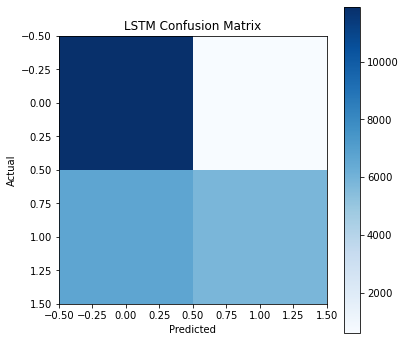

[[11308  1192]
 [ 2260 10240]]


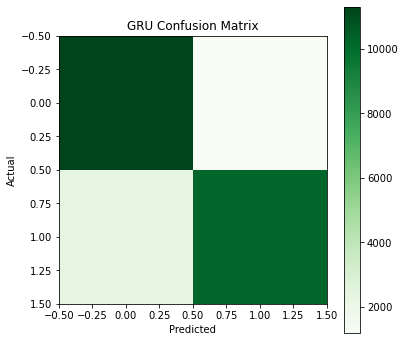

========== LSTM ==========
              precision    recall  f1-score   support

    Negative       0.64      0.95      0.77     12500
    Positive       0.91      0.47      0.62     12500

    accuracy                           0.71     25000
   macro avg       0.77      0.71      0.69     25000
weighted avg       0.77      0.71      0.69     25000


========== GRU ==========
              precision    recall  f1-score   support

    Negative       0.83      0.90      0.87     12500
    Positive       0.90      0.82      0.86     12500

    accuracy                           0.86     25000
   macro avg       0.86      0.86      0.86     25000
weighted avg       0.86      0.86      0.86     25000



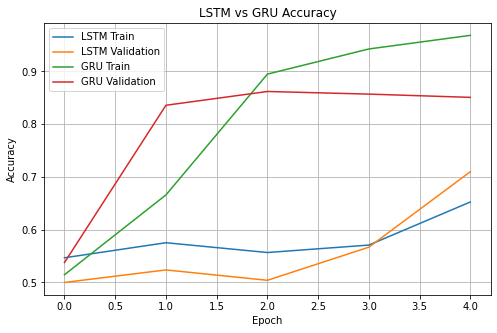

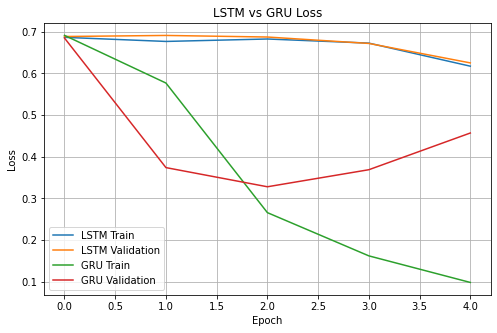

LSTM Training Loss: 5
LSTM Validation Loss: 5
GRU Training Loss: 5
GRU Validation Loss: 5


In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, GRU, Dense, Dropout

from sklearn.metrics import confusion_matrix, classification_report

sample_reviews = [

    "This movie is fantastic",

    "I loved this movie",

    "Worst movie ever",

    "The acting was amazing",

    "The film was boring"

]

tokenizer = Tokenizer(num_words=10000)

tokenizer.fit_on_texts(sample_reviews)

print("Word Index:\n")

print(tokenizer.word_index)

print("\nTokenized Sequences:\n")

sequences = tokenizer.texts_to_sequences(sample_reviews)

print(sequences)

padded_sequences = pad_sequences(

    sequences,

    maxlen=6,

    padding="post",

    truncating="post"

)

print("Padded Sequences:\n")

print(padded_sequences)

vocab_size = 10000

(X_train, y_train), (X_test, y_test) = imdb.load_data(
    num_words=vocab_size
)

print("Training Samples :", X_train.shape)

print("Testing Samples :", X_test.shape)

print("First Review (Encoded)\n")

print(X_train[0])

print("\nLength of Review :", len(X_train[0]))

print("\nSentiment Label :", y_train[0])

word_index = imdb.get_word_index()

reverse_word_index = {
    value + 3: key
    for (key, value) in word_index.items()
}

reverse_word_index[0] = "<PAD>"
reverse_word_index[1] = "<START>"
reverse_word_index[2] = "<UNK>"
reverse_word_index[3] = "<UNUSED>"

decoded_review = " ".join(
    reverse_word_index.get(i, "?")
    for i in X_train[0]
)

print(decoded_review)

max_length = 200

X_train = pad_sequences(

    X_train,

    maxlen=max_length,

    padding="post",

    truncating="post"

)

X_test = pad_sequences(

    X_test,

    maxlen=max_length,

    padding="post",

    truncating="post"

)

print(X_train.shape)

print(X_test.shape)

print("First Review Shape :", X_train[0].shape)

print("First 30 Tokens:\n")

print(X_train[0][:30])

print("\nSentiment :", y_train[0])

embedding_dim = 128

lstm_model = Sequential([

    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        input_length=max_length
    ),

    LSTM(128),

    Dropout(0.5),

    Dense(64, activation="relu"),

    Dense(1, activation="sigmoid")

])

lstm_model.summary()

Model: "sequential"

lstm_model.compile(

    optimizer="adam",

    loss="binary_crossentropy",

    metrics=["accuracy"]

)

history_lstm = lstm_model.fit(

    X_train,
    y_train,

    validation_data=(X_test, y_test),

    epochs=5,

    batch_size=64,

    verbose=1

)

loss_lstm, accuracy_lstm = lstm_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("LSTM Test Loss :", loss_lstm)
print("LSTM Test Accuracy :", accuracy_lstm)

gru_model = Sequential([

    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        input_length=max_length
    ),

    GRU(128),

    Dropout(0.5),

    Dense(64, activation="relu"),

    Dense(1, activation="sigmoid")

])

gru_model.summary()

Model: "sequential_1"

gru_model.compile(

    optimizer="adam",

    loss="binary_crossentropy",

    metrics=["accuracy"]

)

from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history_gru = gru_model.fit(
    X_train,
    y_train,
    validation_data=(X_test, y_test),
    epochs=10,
    batch_size=64,
    callbacks=[early_stop]
)

loss_gru, accuracy_gru = gru_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("GRU Test Loss :", loss_gru)
print("GRU Test Accuracy :", accuracy_gru)

loss_gru, accuracy_gru = gru_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("GRU Test Loss :", loss_gru)
print("GRU Test Accuracy :", accuracy_gru)

import pandas as pd

comparison = pd.DataFrame({

    "Model": ["LSTM", "GRU"],

    "Loss": [loss_lstm, loss_gru],

    "Accuracy": [accuracy_lstm, accuracy_gru]

})

print(comparison)

y_pred_lstm = lstm_model.predict(X_test)

y_pred_lstm = (y_pred_lstm > 0.5).astype(int)

print("LSTM Prediction Shape:", y_pred_lstm.shape)

y_pred_gru = gru_model.predict(X_test)

y_pred_gru = (y_pred_gru > 0.5).astype(int)

print("GRU Prediction Shape:", y_pred_gru.shape)

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm_lstm = confusion_matrix(y_test, y_pred_lstm)

print(cm_lstm)

plt.figure(figsize=(6,6))
plt.imshow(cm_lstm, cmap="Blues")
plt.title("LSTM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.colorbar()
plt.show()

cm_gru = confusion_matrix(y_test, y_pred_gru)

print(cm_gru)

plt.figure(figsize=(6,6))
plt.imshow(cm_gru, cmap="Greens")
plt.title("GRU Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.colorbar()
plt.show()

from sklearn.metrics import classification_report

print("========== LSTM ==========")

print(classification_report(
    y_test,
    y_pred_lstm,
    target_names=["Negative","Positive"]
))

print("\n========== GRU ==========")

print(classification_report(
    y_test,
    y_pred_gru,
    target_names=["Negative","Positive"]
))

plt.figure(figsize=(8,5))

plt.plot(history_lstm.history["accuracy"],
         label="LSTM Train")

plt.plot(history_lstm.history["val_accuracy"],
         label="LSTM Validation")

plt.plot(history_gru.history["accuracy"],
         label="GRU Train")

plt.plot(history_gru.history["val_accuracy"],
         label="GRU Validation")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("LSTM vs GRU Accuracy")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8,5))

plt.plot(history_lstm.history["loss"],
         label="LSTM Train")

plt.plot(history_lstm.history["val_loss"],
         label="LSTM Validation")

plt.plot(history_gru.history["loss"],
         label="GRU Train")

plt.plot(history_gru.history["val_loss"],
         label="GRU Validation")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LSTM vs GRU Loss")
plt.legend()
plt.grid(True)
plt.show()

print("LSTM Training Loss:", len(history_lstm.history["loss"]))
print("LSTM Validation Loss:", len(history_lstm.history["val_loss"]))

print("GRU Training Loss:", len(history_gru.history["loss"]))
print("GRU Validation Loss:", len(history_gru.history["val_loss"]))
